# FieldVision Dataset EDA — Stage 2
## Lightweight NOMS workload characterization

Run this **after Stage 1**. It uses the CSV catalogs saved in:
`~/Downloads/NOMS_Fieldvision/eda_outputs/`

It does not train any model.


In [1]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

HOME = Path.home()
PROJECT_ROOT = HOME / "Downloads" / "NOMS_Fieldvision"
DATASETS_DIR = PROJECT_ROOT / "datasets"
OUTPUT_DIR = PROJECT_ROOT / "eda_outputs"

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"{OUTPUT_DIR} does not exist. Run Stage 1 first."
    )

print("Project root:", PROJECT_ROOT)
print("Using outputs:", OUTPUT_DIR)


Project root: /Users/bwbgv/Downloads/NOMS_Fieldvision
Using outputs: /Users/bwbgv/Downloads/NOMS_Fieldvision/eda_outputs


## 1. Load image catalogs


In [2]:
catalog_files = sorted(OUTPUT_DIR.glob("*_image_catalog.csv"))

print("Catalog files:")
for p in catalog_files:
    print(" -", p.name)

catalogs = {}

for p in catalog_files:
    name = p.name.replace("_image_catalog.csv", "")
    df = pd.read_csv(p)

    # CWD30 may legitimately have zero catalog rows while still zipped.
    catalogs[name] = df

    print(f"\n{name}: {len(df):,} catalog rows")
    if len(df):
        display(df.head())


Catalog files:
 - CWD30_image_catalog.csv
 - LeafySpurge_image_catalog.csv
 - RumexWeeds_image_catalog.csv

CWD30: 0 catalog rows

LeafySpurge: 1,000 catalog rows


,dataset,relative_path,filename,extension,width,height,megapixels,channels_or_mode,format,file_size_mb,error
0,LeafySpurge,data/orthomosaic/orthomosaic_30_20.tif,orthomosaic_30_20.tif,.tif,4096,4096,16.777216,RGBA,TIFF,32.861188,NaN
1,LeafySpurge,data/orthomosaic/orthomosaic_21_18.tif,orthomosaic_21_18.tif,.tif,4096,4096,16.777216,RGBA,TIFF,31.144897,NaN
2,LeafySpurge,data/crop/train/absent/854_8.tif,854_8.tif,.tif,39,39,0.001521,RGBA,TIFF,0.006172,NaN
3,LeafySpurge,data/crop/train/present/824_8.tif,824_8.tif,.tif,39,39,0.001521,RGBA,TIFF,0.006172,NaN
4,LeafySpurge,data/crop/train/present/778_7.tif,778_7.tif,.tif,39,39,0.001521,RGBA,TIFF,0.006172,NaN



RumexWeeds: 1,000 catalog rows


,dataset,relative_path,filename,extension,width,height,megapixels,channels_or_mode,format,file_size_mb,error
0,RumexWeeds,20210807_lundholm/seq10/imgs/20210807_lundholm...,20210807_lundholm_rgb_10_1628331855465779152.png,.png,1920,1200,2.304,RGB,PNG,5.440947,NaN
1,RumexWeeds,20210806_stengard/seq19/imgs/20210806_stengard...,20210806_stengard_rgb_19_1628243594019753431.png,.png,1920,1200,2.304,RGB,PNG,5.301497,NaN
2,RumexWeeds,20210806_stengard/seq14/imgs/20210806_stengard...,20210806_stengard_rgb_14_1628243420021427673.png,.png,1920,1200,2.304,RGB,PNG,5.162028,NaN
3,RumexWeeds,20210908_lundholm/seq13/imgs/20210908_lundholm...,20210908_lundholm_rgb_13_1631093047450103234.png,.png,1920,1200,2.304,RGB,PNG,5.139147,NaN
4,RumexWeeds,20210806_hegnstrup/seq9/imgs/20210806_hegnstru...,20210806_hegnstrup_rgb_9_1628251273719851730.png,.png,1920,1200,2.304,RGB,PNG,4.900403,NaN


## 2. Build real input-workload catalog


In [3]:
workload_rows = []

for dataset_name, df in catalogs.items():
    required = {"file_size_mb", "width", "height", "relative_path"}
    if df.empty or not required.issubset(df.columns):
        print(f"Skipping {dataset_name}: no directly readable image catalog yet.")
        continue

    valid = df.dropna(subset=["file_size_mb", "width", "height"]).copy()

    for _, row in valid.iterrows():
        workload_rows.append({
            "dataset": dataset_name,
            "source_path": row["relative_path"],
            "input_size_mb": row["file_size_mb"],
            "width": row["width"],
            "height": row["height"],
            "megapixels": row.get("megapixels"),
            "format": row.get("format"),
            "mode": row.get("channels_or_mode"),
        })

workload_df = pd.DataFrame(workload_rows)

if workload_df.empty:
    raise RuntimeError("No workload rows were created.")

display(workload_df.head())

display(
    workload_df.groupby("dataset")[
        ["input_size_mb", "megapixels"]
    ].agg(["count", "mean", "median", "min", "max"])
)


Skipping CWD30: no directly readable image catalog yet.


,dataset,source_path,input_size_mb,width,height,megapixels,format,mode
0,LeafySpurge,data/orthomosaic/orthomosaic_30_20.tif,32.861188,4096,4096,16.777216,TIFF,RGBA
1,LeafySpurge,data/orthomosaic/orthomosaic_21_18.tif,31.144897,4096,4096,16.777216,TIFF,RGBA
2,LeafySpurge,data/crop/train/absent/854_8.tif,0.006172,39,39,0.001521,TIFF,RGBA
3,LeafySpurge,data/crop/train/present/824_8.tif,0.006172,39,39,0.001521,TIFF,RGBA
4,LeafySpurge,data/crop/train/present/778_7.tif,0.006172,39,39,0.001521,TIFF,RGBA


input_size_mb                                          megapixels  \
                    count      mean    median       min        max      count   
dataset                                                                         
LeafySpurge          1000  8.603167  4.000870  0.002918  35.108571       1000   
RumexWeeds           1000  5.219250  5.205079  4.762534   5.571625       1000   

                                                      
                 mean    median       min        max  
dataset                                               
LeafySpurge  4.962491  1.048576  0.001521  16.777216  
RumexWeeds   2.304000  2.304000  2.304000   2.304000

## 3. Real input-size distributions


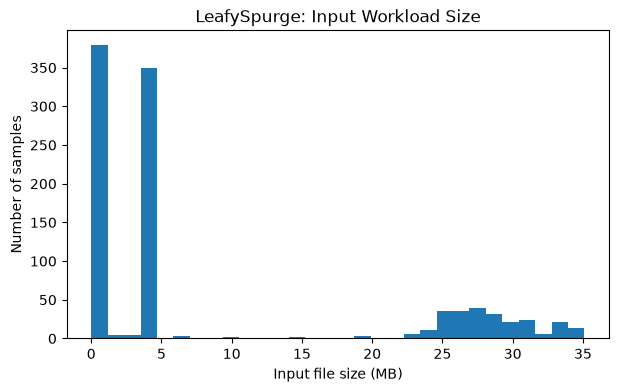

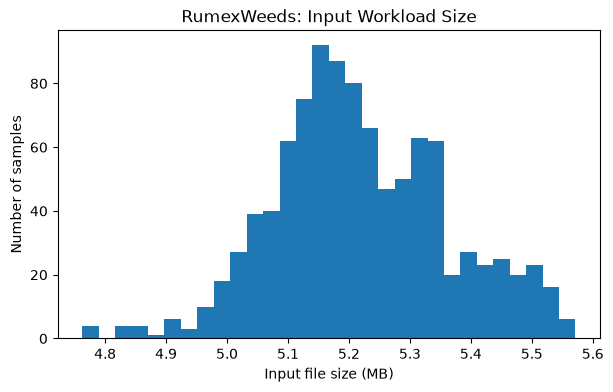

In [4]:
for dataset_name in workload_df["dataset"].unique():
    subset = workload_df[workload_df["dataset"] == dataset_name]

    plt.figure(figsize=(7, 4))
    plt.hist(subset["input_size_mb"], bins=30)
    plt.xlabel("Input file size (MB)")
    plt.ylabel("Number of samples")
    plt.title(f"{dataset_name}: Input Workload Size")
    plt.show()


## 4. Estimate network-transfer time


In [5]:
def transmission_time_seconds(size_mb, bandwidth_mbps):
    return (size_mb * 8) / bandwidth_mbps

bandwidth_scenarios = [2, 5, 10, 25, 50, 100]

network_examples = workload_df.sample(
    min(1000, len(workload_df)),
    random_state=42
).copy()

for bw in bandwidth_scenarios:
    network_examples[f"upload_sec_{bw}Mbps"] = (
        network_examples["input_size_mb"]
        .apply(lambda x: transmission_time_seconds(x, bw))
    )

cols = [c for c in network_examples.columns if c.startswith("upload_sec_")]

display(network_examples.groupby("dataset")[cols].median())


,upload_sec_2Mbps,upload_sec_5Mbps,upload_sec_10Mbps,upload_sec_25Mbps,upload_sec_50Mbps,upload_sec_100Mbps
dataset,,,,,,
LeafySpurge,16.003479,6.401392,3.200696,1.280278,0.640139,0.320070
RumexWeeds,20.828438,8.331375,4.165688,1.666275,0.833138,0.416569


## 5. Locate dataset roots for small preprocessing benchmark


In [6]:
def find_dataset_folder(keyword):
    candidates = [
        p for p in DATASETS_DIR.rglob("*")
        if p.is_dir() and keyword.lower() in p.name.lower()
    ]
    if not candidates:
        return None
    candidates.sort(key=lambda p: len(p.parts))
    return candidates[0]

DATASET_PATHS = {
    "RumexWeeds": find_dataset_folder("rumex"),
    "LeafySpurge": find_dataset_folder("leafy"),
    "CWD30": find_dataset_folder("cwd"),
}

for name, path in DATASET_PATHS.items():
    print(name, "->", path)


RumexWeeds -> /Users/bwbgv/Downloads/NOMS_Fieldvision/datasets/datasets/RumexWeeds
LeafySpurge -> /Users/bwbgv/Downloads/NOMS_Fieldvision/datasets/datasets/LeafySpurge
CWD30 -> /Users/bwbgv/Downloads/NOMS_Fieldvision/datasets/datasets/CWD30


## 6. Lightweight load/decode/resize benchmark — only 50 samples


In [7]:
def benchmark_preprocessing(dataset_name, df, n=50, target_size=(640, 640), seed=42):
    dataset_root = DATASET_PATHS.get(dataset_name)

    if dataset_root is None or df.empty:
        return pd.DataFrame()

    sample = df.dropna(subset=["relative_path"]).copy()

    if len(sample) > n:
        sample = sample.sample(n=n, random_state=seed)

    rows = []

    for _, row in sample.iterrows():
        p = dataset_root / row["relative_path"]

        if not p.exists():
            continue

        try:
            start = time.perf_counter()

            with Image.open(p) as img:
                load_done = time.perf_counter()
                img = img.convert("RGB")
                img = img.resize(target_size)
                resize_done = time.perf_counter()

            rows.append({
                "dataset": dataset_name,
                "relative_path": row["relative_path"],
                "file_size_mb": row.get("file_size_mb"),
                "load_decode_ms": (load_done - start) * 1000,
                "resize_ms": (resize_done - load_done) * 1000,
                "total_preprocess_ms": (resize_done - start) * 1000,
            })
        except Exception:
            pass

    return pd.DataFrame(rows)

preprocessing_results = {}

for dataset_name, df in catalogs.items():
    if dataset_name == "CWD30":
        print("Skipping CWD30 preprocessing while it remains compressed.")
        continue

    result = benchmark_preprocessing(dataset_name, df, n=50)
    preprocessing_results[dataset_name] = result

    print(f"\n{dataset_name}: {len(result)} benchmarked files")
    if len(result):
        display(
            result[[
                "file_size_mb",
                "load_decode_ms",
                "resize_ms",
                "total_preprocess_ms"
            ]].describe()
        )


Skipping CWD30 preprocessing while it remains compressed.

LeafySpurge: 50 benchmarked files


,file_size_mb,load_decode_ms,resize_ms,total_preprocess_ms
count,50.000000,50.000000,50.000000,50.000000
mean,7.544805,1.725422,81.905114,83.630536
std,10.803434,0.707265,142.033531,142.069508
min,0.006172,0.827458,2.230083,3.259250
25%,0.006172,1.293802,7.514135,9.090386
50%,4.000870,1.548375,12.474354,14.101458
75%,4.000870,1.869260,14.308937,15.980542
max,34.295506,5.208333,424.651833,426.414291



RumexWeeds: 50 benchmarked files


,file_size_mb,load_decode_ms,resize_ms,total_preprocess_ms
count,50.000000,50.000000,50.000000,50.000000
mean,5.241932,1.330612,73.680513,75.011125
std,0.197100,0.189655,4.615924,4.658153
min,4.832908,0.876333,70.277250,71.510084
25%,5.086478,1.237907,71.691802,73.155833
50%,5.221366,1.308188,72.688208,74.069729
75%,5.402429,1.455656,73.701010,75.183052
max,5.571625,1.725333,102.212125,103.821125


## 7. Save workload outputs


In [8]:
workload_df.to_csv(
    OUTPUT_DIR / "image_workload_catalog.csv",
    index=False
)

network_examples.to_csv(
    OUTPUT_DIR / "network_transfer_examples.csv",
    index=False
)

for name, df in preprocessing_results.items():
    if len(df):
        df.to_csv(
            OUTPUT_DIR / f"{name}_preprocessing.csv",
            index=False
        )

print("Saved outputs to:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", p.name)


Saved outputs to: /Users/bwbgv/Downloads/NOMS_Fieldvision/eda_outputs
 - CWD30_image_catalog.csv
 - LeafySpurge_image_catalog.csv
 - LeafySpurge_preprocessing.csv
 - RumexWeeds_image_catalog.csv
 - RumexWeeds_preprocessing.csv
 - dataset_summary.csv
 - image_workload_catalog.csv
 - leafyspurge_semantics.csv
 - network_transfer_examples.csv
